# The gap between measured and published paleomagnetic data

Figure 1 of *A community standard in FAIR paleomagnetic data publication*.

The notebook brings together three sources:

* the **MagIC database**: which data levels each study archives (measurements, specimen directions, site means, poles);
* **Scopus**: the number of papers per year that use plate or paleogeographic reconstructions;
* the **Global Paleomagnetic Database** (GPMDB; Pisarevsky et al., 2022): the papers that report paleomagnetic poles.

It first draws three figures, and the last cell combines them into the figure of the paper:

* **(a)** use vs. production of paleomagnetic poles;
* **(b)** what sits behind a pole: demagnetization steps, specimens, samples, sites and locations per study;
* **(c)** published poles and the data that MagIC holds for them.

All data are read from the CSV files in `data/`, so the notebook runs in seconds and without a connection. Each file
is written by the cell that reads it: delete a file (or set `RESCAN`) and that cell builds it again from its source.
The selection of MagIC studies and the definition of a demagnetization step follow N. Swanson-Hysell's script
`make_figure1b_magic_levels.py` ([gist](https://gist.github.com/Swanson-Hysell/85874f936bacdbf7aa5e62d4d6c7db7d)).

In [1]:
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path
import re
import time
import unicodedata

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests

DATA = Path("data")
RESCAN = False   # True: list and scan all public MagIC contributions again (~20 min) and count the new studies
N_WORKERS = 4    # parallel requests to MagIC

## 1. MagIC: the data levels of each study

**Scan** (`data/magic_scan.csv`). The public contributions are listed and the newest one is kept for each reference.
Each is then read up to its measurements table to record which tables hold data: locations with a pole, sites and
specimens with a direction (`dir_dec`), and whether there are measurements.

The MagIC search API returns at most 10,000 rows per query, so counts for the whole database cannot come from search
queries; each contribution is read instead.

In [2]:
MAGIC_API = "https://api.earthref.org/v1/MagIC"
SCAN_FILE = DATA / "magic_scan.csv"
COUNTS_FILE = DATA / "magic_level_counts.csv"


def iter_tables(contribution_id):
    """Stream a public MagIC contribution as (table name, row dict) pairs."""
    with requests.get(f"{MAGIC_API}/data", params={"id": contribution_id}, headers={"Accept": "text/plain"},
                      stream=True, timeout=600) as response:
        response.raise_for_status()
        if response.status_code != 200:  # 204: nothing returned
            raise requests.HTTPError(f"HTTP {response.status_code}")
        response.encoding = response.encoding or "utf-8"
        table, header = None, None
        for line in response.iter_lines(decode_unicode=True):
            if not line or line.startswith(">>>>"):
                continue
            if line.startswith("tab"):
                table, header = line.split("\t")[-1].strip(), None
            elif header is None:
                header = line.split("\t")
            else:
                yield table, dict(zip(header, line.split("\t")))


def latest_contributions():
    """The newest public contribution for each reference."""
    response = requests.get(f"{MAGIC_API}/search/contributions", params={"n_max_rows": 10000}, timeout=300)
    response.raise_for_status()
    latest = {}
    for contribution in response.json()["results"]:
        reference = (contribution.get("reference") or f"no-reference-{contribution['id']}").lower()
        if reference not in latest or contribution["id"] > latest[reference]["id"]:
            latest[reference] = contribution
    return sorted(latest.values(), key=lambda c: c["id"])


def scan_contribution(contribution):
    """Which tables of a contribution hold data, reading up to its first measurement."""
    record = dict(id=contribution["id"], reference=contribution.get("reference", ""), n_loc=0, n_loc_pole=0,
                  n_site=0, n_site_dir=0, n_samp=0, n_spec=0, n_spec_dir=0, has_meas=False)
    for table, row in iter_tables(contribution["id"]):
        if table == "measurements":
            record["has_meas"] = True
            break
        if table == "locations":
            record["n_loc"] += 1
            record["n_loc_pole"] += bool(row.get("pole_lat", "").strip())
        elif table == "sites":
            record["n_site"] += 1
            record["n_site_dir"] += bool(row.get("dir_dec", "").strip())
        elif table == "samples":
            record["n_samp"] += 1
        elif table == "specimens":
            record["n_spec"] += 1
            record["n_spec_dir"] += bool(row.get("dir_dec", "").strip())
    return record


def run_parallel(function, items, tries=3):
    """function(item) for every item, a few at a time and retrying failures.

    Returns one dict per item; a failed item gives {"item": item, "err": message}.
    """
    def safe(item):
        for attempt in range(tries):
            try:
                return function(item)
            except Exception as error:
                message = repr(error)[:200]
                time.sleep(10 * (attempt + 1))
        return {"item": item, "err": message}

    with ThreadPoolExecutor(max_workers=N_WORKERS) as executor:
        return list(executor.map(safe, items))


if RESCAN or not SCAN_FILE.exists():
    records = run_parallel(scan_contribution, latest_contributions())
    records = [r if "err" not in r else dict(id=r["item"]["id"], reference=r["item"].get("reference", ""), err=r["err"])
               for r in records]
    pd.DataFrame(records).to_csv(SCAN_FILE, index=False)

scan = pd.read_csv(SCAN_FILE)
scanned = scan[scan["err"].isna()].drop(columns="err").astype({"has_meas": bool})
print(f"{len(scan)} contributions (newest per reference), {len(scan) - len(scanned)} could not be read; "
      f"{scanned['has_meas'].sum()} have measurements")

4474 contributions (newest per reference), 3 could not be read; 357 have measurements


**Counts** (`data/magic_level_counts.csv`). Every study with measurements is read in full to count:

* **demagnetization steps**: measurement rows whose method codes include a zero-field step (`LT-NO`, `LT-AF-Z`,
  `LT-T-Z`, `LT-M-Z`, `LT-LT-Z`) or a demagnetization protocol (`LP-DIR-*`, `LP-AF`, `LP-T`, `LP-U`, `LP-NO`).
  Contributions code their demagnetization data in different ways, and many carry only one of the two kinds of code,
  so both are needed;
* **specimens** with at least one demagnetization step;
* **samples**: sample names in the samples table;
* **sites** with a mean direction;
* **locations**: location names.

Each name counts once, however many rows (fits, coordinate systems) it has. Studies that are not in the file yet are
counted and added to it.

In [3]:
# A measurement is a demagnetization step if its method codes include a zero-field treatment (LT) code or a
# demagnetization protocol (LP) code.
DEMAG_LT_CODES = {"LT-NO", "LT-AF-Z", "LT-T-Z", "LT-M-Z", "LT-LT-Z"}
DEMAG_LP_CODES = {"LP-AF", "LP-T", "LP-U", "LP-NO"}


def is_demag_step(method_codes):
    codes = {code.strip() for code in method_codes.split(":")}
    return bool(codes & DEMAG_LT_CODES or codes & DEMAG_LP_CODES or any(code.startswith("LP-DIR") for code in codes))


def count_levels(contribution_id):
    """Demagnetization steps and names at each level of a study."""
    n_measurements = demag_steps = 0
    specimens, samples, sites, locations = set(), set(), set(), set()
    for table, row in iter_tables(contribution_id):
        if table == "measurements":
            n_measurements += 1
            if is_demag_step(row.get("method_codes", "")):
                demag_steps += 1
                specimens.add(row.get("specimen", ""))
        elif table == "samples":
            samples.add(row.get("sample", ""))
        elif table == "sites":
            if row.get("dir_dec", "").strip():
                sites.add(row.get("site", ""))
        elif table == "locations":
            locations.add(row.get("location", ""))
    return dict(id=contribution_id, n_measurements=n_measurements, demag_steps=demag_steps,
                specimens=len(specimens - {""}), samples=len(samples - {""}), sites=len(sites - {""}),
                locations=len(locations - {""}))


counts = pd.read_csv(COUNTS_FILE) if COUNTS_FILE.exists() else pd.DataFrame(columns=["id"])
todo = sorted(set(scanned.loc[scanned["has_meas"], "id"]) - set(counts["id"]))
if todo:
    results = run_parallel(count_levels, todo)
    new = pd.DataFrame([r for r in results if "err" not in r])
    counts = pd.concat([counts, new]).astype(int).sort_values("id")
    counts.to_csv(COUNTS_FILE, index=False)
    print(f"{len(new)} studies counted; could not be read: {[r['item'] for r in results if 'err' in r]}")

studies = scanned.merge(counts, on="id", how="left")

# The deepest level at which each study archives directional data
LEVELS = ["Measurements", "Specimen directions", "Site means", "Poles only"]
has_level = [studies["demag_steps"] > 0, studies["n_spec_dir"] > 0, studies["n_site_dir"] > 0, studies["n_loc_pole"] > 0]
studies["level"] = None
for level, has in reversed(list(zip(LEVELS, has_level))):
    studies.loc[has, "level"] = level
studies["level"].value_counts().reindex(LEVELS).to_frame("studies")

,studies
Measurements,326
Specimen directions,41
Site means,753
Poles only,3017


## 2. Scopus: papers that use reconstructions

`data/scopus_reconstruction_papers.csv` holds the number of Scopus documents per publication year whose title,
abstract or keywords match the query below (counted on 29 October 2026). Building the file again needs an Elsevier
API key and [`pybliometrics`](https://pybliometrics.readthedocs.io).

In [4]:
SCOPUS_FILE = DATA / "scopus_reconstruction_papers.csv"
SCOPUS_QUERY = ('TITLE-ABS-KEY("plate reconstruction*" OR "paleogeographic reconstruction*" '
                'OR "palaeogeographic reconstruction*" OR "plate tectonic reconstruction*")')
YEARS = range(1960, 2026)

if not SCOPUS_FILE.exists():
    import pybliometrics
    from pybliometrics.scopus import ScopusSearch
    pybliometrics.init()
    papers = [ScopusSearch(f"({SCOPUS_QUERY}) AND PUBYEAR IS {year}", download=False).get_results_size()
              for year in YEARS]
    pd.DataFrame({"year": list(YEARS), "papers": papers}).to_csv(SCOPUS_FILE, index=False)

reconstruction_papers = pd.read_csv(SCOPUS_FILE, index_col="year")["papers"]

## 3. GPMDB: papers that report poles

`data/gpmdb_papers.csv` lists the papers of the GPMDB, one row each, with the number of poles they report. It is
built from an export of all records of the online database ([gpmdb.net](http://www.gpmdb.net), exported on
27 October 2026), which is not part of this repository. A few records of the export are broken over two lines, and
some page ranges were turned into dates by a spreadsheet (`1-20` became `Jan-20`); both are repaired here.

The GPMDB is only partly updated after about 2005, so it is a reference set of published poles and not a complete
count. `GPMDB_LAST_YEAR` is the last publication year that the export covers fully.

In [5]:
GPMDB_EXPORT = DATA / "gpmdb_search_results.csv"
GPMDB_FILE = DATA / "gpmdb_papers.csv"
GPMDB_LAST_YEAR = 2024
MONTHS = {month: i + 1 for i, month in enumerate("Jan Feb Mar Apr May Jun Jul Aug Sep Oct Nov Dec".split())}


def undo_date(pages):
    """A page range that a spreadsheet read as a date: '1-20' became 'Jan-20', '1-10' became '01-Oct'."""
    m = re.fullmatch(r"(\d{1,2})-([A-Z][a-z]{2})|([A-Z][a-z]{2})-(\d{2})", pages.strip())
    if not m or (m[2] or m[3]) not in MONTHS:
        return pages
    return f"{int(m[1])}-{MONTHS[m[2]]}" if m[1] else f"{MONTHS[m[3]]}-{int(m[4])}"


def read_gpmdb_export(path):
    """The records of the GPMDB export, with broken lines joined and page ranges restored."""
    raw = pd.read_csv(path, dtype=str, keep_default_na=False)
    rows = []
    for row in raw.values.tolist():
        if rows and not row[0].strip().isdigit():  # no REFNO: the rest of the record above
            previous = rows[-1]
            k = max(i for i, value in enumerate(previous) if value.strip())  # the field the break fell in
            previous[k + 1:] = row[1:len(previous) - k]
        else:
            rows.append(row)
    records = pd.DataFrame(rows, columns=raw.columns)
    records["Pages"] = records["Pages"].map(undo_date)
    return records.replace(r"^\s*$", np.nan, regex=True).astype({"REFNO": int, "ResultNo": int, "Year": int})


if not GPMDB_FILE.exists():
    (read_gpmdb_export(GPMDB_EXPORT).groupby("REFNO")
     .agg(year=("Year", "first"), authors=("Authors", "first"), journal=("Journal", "first"),
          volume=("Volume", "first"), pages=("Pages", "first"), poles=("ResultNo", "nunique"))
     .to_csv(GPMDB_FILE))

gpmdb = pd.read_csv(GPMDB_FILE, dtype={"volume": str, "pages": str})
pole_papers = gpmdb.groupby("year").size().reindex(range(YEARS[0], GPMDB_LAST_YEAR + 1), fill_value=0)
print(f"GPMDB: {gpmdb['poles'].sum()} poles from {len(gpmdb)} papers, {gpmdb['year'].min()}-{gpmdb['year'].max()}")

GPMDB: 10421 poles from 4196 papers, 1925-2025


## 4. Which GPMDB papers have data in MagIC?

Most GPMDB records have no DOI, so the papers are matched to the MagIC studies through their bibliographic details.
`data/magic_references.csv` holds the publication year, volume, first page and first author of each DOI in MagIC,
from [OpenAlex](https://openalex.org); DOIs that are not in the file yet are looked up and added.

A paper and a study match by, in this order:

1. the DOI written in the GPMDB record;
2. volume and first page, with publication years within one year;
3. an article number (e.g. `B02101`, `e2020TC006168`) that is part of the DOI;
4. first page, first author and year, where the GPMDB record has no volume;
5. first author and year, for the MagIC studies whose reference is a citation without a DOI (`SMITH ET AL. (1985)`):
   these are the legacy uploads of the GPMDB poles to MagIC in 2006–2007.

A paper takes the deepest level of the studies it matches. Papers that cannot be matched count as "not in MagIC",
so the shares in MagIC are lower bounds.

In [6]:
OPENALEX_API = "https://api.openalex.org/works"
REFERENCES_FILE = DATA / "magic_references.csv"
DOI_RE = r"(10\.\d{4,9}/[^\s,]+)"


def find_doi(text):
    return text.fillna("").str.extract(DOI_RE, flags=re.I, expand=False).str.lower().str.rstrip(".;")


def openalex_works(dois):
    """Publication year, volume, first page and first author of each DOI (empty where OpenAlex has no record)."""
    def query(part):
        response = requests.get(OPENALEX_API, timeout=120, params={
            "filter": "doi:" + "|".join(part), "select": "doi,publication_year,biblio,authorships", "per-page": 200})
        response.raise_for_status()
        found = {}
        for work in response.json()["results"]:
            authors, biblio = work.get("authorships") or [], work.get("biblio") or {}
            found[work["doi"].replace("https://doi.org/", "").lower()] = dict(
                ref_year=work["publication_year"], ref_volume=biblio.get("volume"),
                ref_first_page=biblio.get("first_page"),
                ref_first_author=(authors[0].get("author") or {}).get("display_name") if authors else None)
        return found

    found = {}
    for k in range(0, len(dois), 50):
        part = [doi for doi in dois[k:k + 50] if "|" not in doi]
        try:
            found.update(query(part))
        except requests.RequestException:  # one odd DOI can break the whole request: ask one at a time
            for doi in part:
                try:
                    found.update(query([doi]))
                except requests.RequestException:
                    pass
        time.sleep(0.2)
    return pd.DataFrame([dict(doi=doi, **found.get(doi, {})) for doi in dois])


studies["doi"] = find_doi(studies["reference"])
references = (pd.read_csv(REFERENCES_FILE, dtype={"ref_volume": str, "ref_first_page": str})
              if REFERENCES_FILE.exists() else pd.DataFrame(columns=["doi"]))
todo = sorted(set(studies["doi"].dropna()) - set(references["doi"]))
if todo:
    references = pd.concat([references, openalex_works(todo)]).sort_values("doi")
    references.to_csv(REFERENCES_FILE, index=False)
print(f"{studies['doi'].notna().sum()} studies with a DOI; publication details found for "
      f"{references['ref_year'].notna().sum()} of {len(references)} DOIs")

2374 studies with a DOI; publication details found for 2259 of 2372 DOIs


In [7]:
def norm_name(name):
    """A name in lower-case ASCII letters only."""
    return re.sub(r"[^a-z]", "", unicodedata.normalize("NFKD", str(name)).encode("ascii", "ignore").decode().lower())


def first_page(pages):
    """The first page or article number of a page range, in lower case."""
    if pd.isna(pages):
        return None
    m = re.match(r"([A-Za-z]*\d+[A-Za-z0-9]*)", re.sub(r"(?i)doi:\S+", "", str(pages)).strip())
    return m.group(1).lower() if m else None


def volume_number(volume):
    m = None if pd.isna(volume) else re.match(r"\s*(\d+)", str(volume))
    return m.group(1) if m else None


def same_surname(a, b):
    if not a or not b or min(len(a), len(b)) < 3:
        return False
    return a == b or (min(len(a), len(b)) >= 5 and (a.endswith(b) or b.endswith(a)))


papers = gpmdb.copy()
papers["doi"] = find_doi(papers["pages"].astype(str) + " " + papers["volume"].astype(str))
papers["vol"], papers["p1"] = papers["volume"].map(volume_number), papers["pages"].map(first_page)
papers["sur"] = papers["authors"].map(lambda authors: norm_name(str(authors).split(",")[0]))

magic = studies.dropna(subset=["level"])[["id", "reference", "doi", "level"]].merge(references, on="doi", how="left")
magic["lev"] = magic["level"].map(LEVELS.index)  # 0 = measurements ... 3 = poles only
magic["myear"] = magic["ref_year"]
magic["vol"], magic["p1"] = magic["ref_volume"].map(volume_number), magic["ref_first_page"].map(first_page)
magic["sur"] = magic["ref_first_author"].map(lambda name: norm_name(name.split()[-1]) if isinstance(name, str) else None)
with_doi, legacy = magic[magic["doi"].notna()], magic[magic["doi"].isna()].copy()
citation = legacy["reference"].str.extract(r"(?i)^\s*([^(&]+?)(?:\s+et al\.?|\s*&.*)?\s*\((\d{4})\)")
legacy["sur"] = citation[0].map(lambda name: norm_name(name.split()[-1]) if isinstance(name, str) else None)
legacy["myear"] = pd.to_numeric(citation[1], errors="coerce")

near = lambda m: (m["year"] - m["myear"]).abs() <= 1
surnames_agree = lambda m: np.array([same_surname(a, b) for a, b in zip(m["sur"], m["sur_m"])], dtype=bool)
matches = []
m = papers.dropna(subset=["doi"]).merge(with_doi[["doi", "id", "lev"]], on="doi")                       # 1
matches.append(m.assign(rule="DOI"))
m = papers.dropna(subset=["vol", "p1"]).merge(with_doi.dropna(subset=["vol", "p1"]), on=["vol", "p1"],
                                              suffixes=("", "_m"))                                     # 2
matches.append(m[near(m)].assign(rule="volume + first page"))
rows = []                                                                                              # 3
for paper in papers[papers["p1"].str.len().fillna(0) >= 8].itertuples():
    hit = with_doi[with_doi["doi"].str.contains(paper.p1.lstrip("e"), regex=False)
                   & ((with_doi["myear"] - paper.year).abs() <= 1)]
    rows += [dict(REFNO=paper.REFNO, id=i, lev=lev) for i, lev in zip(hit["id"], hit["lev"])]
matches.append(pd.DataFrame(rows, columns=["REFNO", "id", "lev"]).assign(rule="article number in DOI"))
m = papers[papers["vol"].isna()].dropna(subset=["p1"]).merge(with_doi.dropna(subset=["p1", "sur"]), on="p1",
                                                              suffixes=("", "_m"))                     # 4
matches.append(m[near(m) & surnames_agree(m)].assign(rule="first page + author + year"))
m = papers.merge(legacy.dropna(subset=["sur", "myear"]), left_on="year", right_on="myear", suffixes=("", "_m"))  # 5
matches.append(m[surnames_agree(m)].assign(rule="author + year (legacy)"))
matches = pd.concat([m[["REFNO", "id", "lev", "rule"]] for m in matches]).drop_duplicates(["REFNO", "id"])

STATUS = LEVELS + ["Not in MagIC"]
papers["status"] = papers["REFNO"].map(matches.groupby("REFNO")["lev"].min()).map(dict(enumerate(LEVELS)))
papers["status"] = pd.Categorical(papers["status"].fillna("Not in MagIC"), STATUS, ordered=True)
papers["decade"] = papers["year"] // 10 * 10
by_decade = papers.groupby(["decade", "status"], observed=False).size().unstack(fill_value=0).loc[1950:, STATUS]
print("papers matched by:", matches.drop_duplicates("REFNO")["rule"].value_counts().to_dict())
by_decade.assign(papers=by_decade.sum(axis=1))

papers matched by: {'author + year (legacy)': 1813, 'volume + first page': 1401, 'DOI': 33, 'article number in DOI': 7, 'first page + author + year': 2}


status,Measurements,Specimen directions,Site means,Poles only,Not in MagIC,papers
decade,,,,,,
1950,0,0,0,65,5,70
1960,0,0,22,289,24,335
1970,0,1,66,739,42,848
1980,2,1,60,841,116,1020
1990,2,5,57,773,68,905
2000,8,0,40,249,200,497
2010,7,2,11,1,332,353
2020,6,1,3,0,153,163


## 5. Figures

The three panels are drawn one by one, each with the numbers that the paper quotes from it.

In [8]:
# A one-hue ordinal ramp: darker = deeper level archived; grey = not in MagIC
LEVEL_COLORS = dict(zip(LEVELS, ["#0d366b", "#1c5cab", "#3987e5", "#86b6ef"]))
STATUS_COLORS = {**LEVEL_COLORS, "Not in MagIC": "#d9d8d2"}
INK, INK2, MUTED, GRID = "#0b0b0b", "#52514e", "#898781", "#e1e0d9"

plt.rcParams.update({
    "font.family": "sans-serif", "font.sans-serif": ["Helvetica", "Arial", "DejaVu Sans"],
    "font.size": 7.5, "axes.titlesize": 8.5, "axes.labelsize": 7.5,
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
    "axes.spines.top": False, "axes.spines.right": False, "pdf.fonttype": 42, "figure.dpi": 150,
})


def title(ax, text, subtitle=None):
    ax.set_title(text, loc="left", color=INK, fontweight="bold", pad=16 if subtitle else 5)
    if subtitle:
        ax.text(0, 1.012, subtitle, transform=ax.transAxes, color=INK2, fontsize=6.5, va="bottom")

### (a) Use vs. production of poles

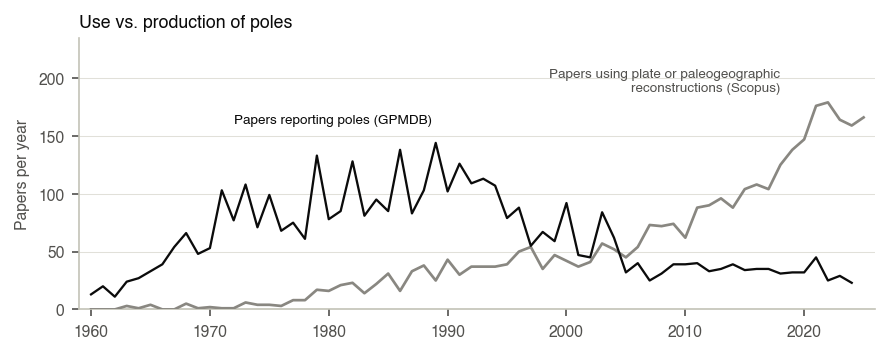

Papers using reconstructions: 19 per year in 1980-84, 165 per year in 2020-24 (8.6 times more)
Papers reporting poles (GPMDB): most in 1989 (144); 117 per year in 1988-92, 66 in 2000-04


In [9]:
def plot_use_vs_production(ax, label=""):
    ax.plot(reconstruction_papers.index, reconstruction_papers.values, color=MUTED, lw=1.3, zorder=3)
    ax.plot(pole_papers.index, pole_papers.values, color=INK, lw=1.1, zorder=3)
    ax.annotate("Papers using plate or paleogeographic\nreconstructions (Scopus)", (2018, 186),
                ha="right", va="bottom", color=INK2, fontsize=6.5)
    ax.annotate("Papers reporting poles (GPMDB)", (1972, 158), ha="left", va="bottom", color=INK, fontsize=6.5)
    ax.set_xlim(1959, 2026)
    ax.set_ylim(0, 235)
    ax.grid(axis="y", color=GRID, lw=0.5, zorder=1)
    ax.set_ylabel("Papers per year")
    title(ax, f"{label}Use vs. production of poles")


fig, ax = plt.subplots(figsize=(6.85, 2.4))
plot_use_vs_production(ax)
plt.show()

early, recent = reconstruction_papers.loc[1980:1984].mean(), reconstruction_papers.loc[2020:2024].mean()
print(f"Papers using reconstructions: {early:.0f} per year in 1980-84, {recent:.0f} per year in 2020-24 "
      f"({recent / early:.1f} times more)")
print(f"Papers reporting poles (GPMDB): most in {pole_papers.idxmax()} ({pole_papers.max()}); "
      f"{pole_papers.loc[1988:1992].mean():.0f} per year in 1988-92, {pole_papers.loc[2000:2004].mean():.0f} in 2000-04")

### (b) What sits behind a pole

The studies with demagnetization steps and at least one site with a mean direction. Few of them upload a pole, so
their locations (the level at which MagIC stores poles) stand in for the poles. Boxes span the 25th–75th percentiles
and whiskers the 10th–90th; the dots and labels give the median.

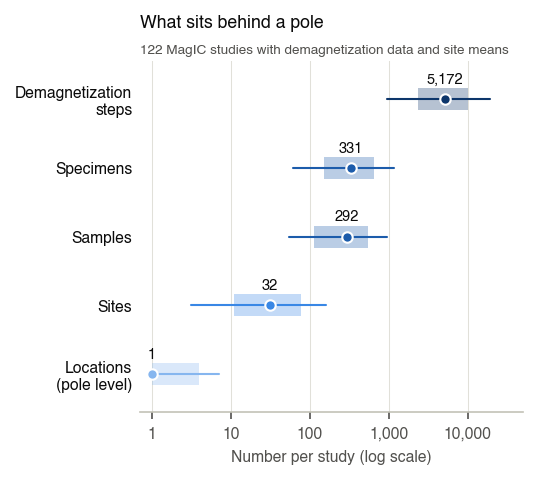

122 studies with demagnetization steps and site means


,demag_steps,specimens,samples,sites,locations
count,122.0,122.0,122.0,122.0,122.0
mean,10324.0,587.0,554.0,256.0,3.0
std,18428.0,1001.0,1406.0,1520.0,5.0
min,39.0,17.0,1.0,1.0,1.0
10%,941.0,61.0,55.0,3.0,1.0
25%,2352.0,153.0,112.0,11.0,1.0
50%,5172.0,331.0,292.0,32.0,1.0
75%,9988.0,646.0,546.0,78.0,4.0
90%,19203.0,1164.0,954.0,162.0,7.0
max,126247.0,8905.0,14497.0,15900.0,41.0


In [10]:
behind_a_pole = studies[(studies["demag_steps"] > 0) & (studies["n_site_dir"] > 0)]
ROWS = [  # label, column, colour of the level it belongs to
    ("Demagnetization\nsteps", "demag_steps", LEVEL_COLORS["Measurements"]),
    ("Specimens", "specimens", LEVEL_COLORS["Specimen directions"]),
    ("Samples", "samples", LEVEL_COLORS["Specimen directions"]),
    ("Sites", "sites", LEVEL_COLORS["Site means"]),
    ("Locations\n(pole level)", "locations", LEVEL_COLORS["Poles only"]),
]


def plot_behind_a_pole(ax, label=""):
    for i, (name, column, color) in enumerate(ROWS):
        values = behind_a_pole[column][behind_a_pole[column] > 0]
        p10, p25, p50, p75, p90 = values.quantile([0.1, 0.25, 0.5, 0.75, 0.9])
        ax.plot([p10, p90], [-i, -i], color=color, lw=1, solid_capstyle="round", zorder=2)
        ax.add_patch(plt.Rectangle((p25, -i - 0.16), p75 - p25, 0.32, color=color, alpha=0.3, lw=0, zorder=2))
        ax.plot(p50, -i, "o", ms=5, color=color, mec="white", mew=1, zorder=4)
        ax.annotate(f"{p50:,.0f}", (p50, -i), xytext=(0, 6), textcoords="offset points", ha="center", va="bottom",
                    color=INK, fontsize=7)
    ax.set_xscale("log")
    ax.set_xlim(0.7, 5e4)
    ax.set_xticks([1, 10, 100, 1e3, 1e4])
    ax.set_xticklabels(["1", "10", "100", "1,000", "10,000"])
    ax.minorticks_off()
    ax.set_ylim(-len(ROWS) + 0.45, 0.55)
    ax.set_yticks([-i for i in range(len(ROWS))])
    ax.set_yticklabels([row[0] for row in ROWS])
    ax.tick_params(axis="y", length=0, labelcolor=INK)
    ax.spines["left"].set_visible(False)
    ax.grid(axis="x", color=GRID, lw=0.5, zorder=0)
    ax.set_xlabel("Number per study (log scale)")
    title(ax, f"{label}What sits behind a pole",
          f"{len(behind_a_pole)} MagIC studies with demagnetization data and site means")


fig, ax = plt.subplots(figsize=(3.3, 3.1))
plot_behind_a_pole(ax)
plt.show()

print(f"{len(behind_a_pole)} studies with demagnetization steps and site means")
behind_a_pole[[row[1] for row in ROWS]].describe(percentiles=[0.1, 0.25, 0.5, 0.75, 0.9]).round(0)

### (c) Published poles: their data in MagIC

The papers of the GPMDB by decade of publication, coloured by the deepest level of their data in MagIC.

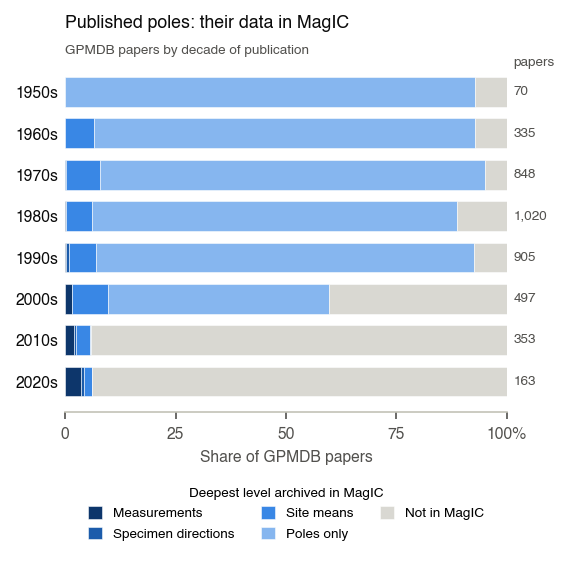

GPMDB papers published since 2005: 683; 48 (7%) have data in MagIC, 17 (2%) with demagnetization data
All GPMDB papers: 4196; 294 (7%) have site means or deeper data in MagIC


In [11]:
def plot_gpmdb_in_magic(ax, label="", legend=True):
    share = by_decade.div(by_decade.sum(axis=1), axis=0)[::-1] * 100
    left = np.zeros(len(share))
    for status in STATUS:
        ax.barh(range(len(share)), share[status], 0.72, left=left, color=STATUS_COLORS[status], edgecolor="white",
                linewidth=0.25, label=status, zorder=2)
        left += share[status].values
    for y, n in enumerate(by_decade.sum(axis=1)[::-1]):
        ax.text(101.5, y, f"{n:,}", va="center", ha="left", color=INK2, fontsize=6.5)
    ax.text(101.5, len(share) - 0.45, "papers", va="bottom", ha="left", color=INK2, fontsize=6.5)
    ax.set_xlim(0, 100)
    ax.set_xticks([0, 25, 50, 75, 100])
    ax.set_xticklabels(["0", "25", "50", "75", "100%"])
    ax.set_yticks(range(len(share)))
    ax.set_yticklabels([f"{decade}s" for decade in share.index])
    ax.tick_params(axis="y", length=0, labelcolor=INK)
    ax.spines["left"].set_visible(False)
    ax.set_xlabel("Share of GPMDB papers")
    title(ax, f"{label}Published poles: their data in MagIC", "GPMDB papers by decade of publication")
    if legend:
        ax.legend(title="Deepest level archived in MagIC", title_fontsize=6.5, ncol=3, loc="upper center",
                  bbox_to_anchor=(0.5, -0.18), frameon=False, fontsize=6.5, handlelength=1, handleheight=1)


fig, ax = plt.subplots(figsize=(3.8, 3.1))
plot_gpmdb_in_magic(ax)
plt.show()

since_2005 = papers[papers["year"] >= 2005]
in_magic, with_measurements = since_2005["status"] != "Not in MagIC", since_2005["status"] == "Measurements"
print(f"GPMDB papers published since 2005: {len(since_2005)}; {in_magic.sum()} ({in_magic.mean():.0%}) have data in "
      f"MagIC, {with_measurements.sum()} ({with_measurements.mean():.0%}) with demagnetization data")
deeper = papers["status"] < "Poles only"
print(f"All GPMDB papers: {len(papers)}; {deeper.sum()} ({deeper.mean():.0%}) have site means or deeper data in MagIC")

## 6. Figure 1 of the paper

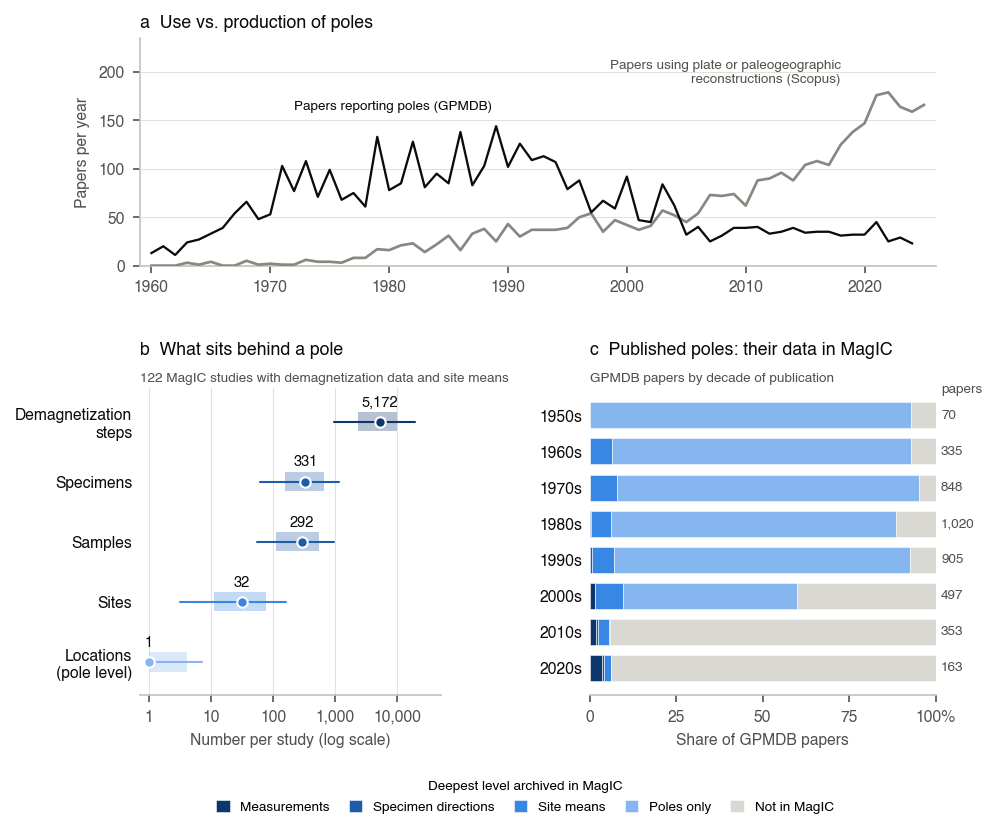

In [12]:
fig = plt.figure(figsize=(6.85, 5.8))  # 174 mm, full page width
grid = fig.add_gridspec(2, 2, height_ratios=[0.95, 1.28], width_ratios=[1, 1.15], wspace=0.46, hspace=0.46)
plot_use_vs_production(fig.add_subplot(grid[0, :]), label="a  ")
plot_behind_a_pole(fig.add_subplot(grid[1, 0]), label="b  ")
ax = fig.add_subplot(grid[1, 1])
plot_gpmdb_in_magic(ax, label="c  ", legend=False)
fig.legend(*ax.get_legend_handles_labels(), title="Deepest level archived in MagIC", title_fontsize=6.5, ncol=5,
           loc="upper center", bbox_to_anchor=(0.5, 0.04), frameon=False, fontsize=6.5,
           handlelength=1, handleheight=1, columnspacing=1.4)
fig.savefig("data_gap.pdf", bbox_inches="tight")
fig.savefig("data_gap.png", dpi=600, bbox_inches="tight")
plt.show()